# Report figures and tables

Regenerates every table and figure in the report from the files the runs saved, with the
functions in `src/tiny_timbre/analyze.py` (no logic lives here). Outputs go to `report/figures/`
and `report/tables/`.

**Needs, in the repo:** `data/results/*_test_scores.npz` and the two `*_embeddings.npz` (from Drive's
`results/`), `checkpoints/*.best.pt` (from Drive's `checkpoints/`), `data/fma_metadata/`, and for the
gradient and feature-map cells the local spectrogram cache `data/mels_medium/` (any number of clips).
Run with `uv run --group demo jupyter lab` or the VS Code notebook UI, top to bottom.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # paths below are relative to the repo root

import numpy as np
import pandas as pd
import yaml
from tiny_timbre import analyze as A

RESULTS, META_DIR, MELS_DIR = "data/results", "data/fma_metadata", "data/mels_medium"
FIG, TAB = Path("report/figures"), Path("report/tables")
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

FLAT = ["e0_cnn_flat", "e1_flat_s1", "e1_flat_s2"]          # E1 flat, seeds 0-2
GCN = ["e1_gcn_s0", "e1_gcn_s1", "e1_gcn_s2"]               # E1 GCN, seeds 0-2
CNN_RUNS = FLAT + GCN + ["e2_gcn_cooc_s0", "e3_gcn_1layer_s0", "e3_gcn_3layer_s0"]

meta = A.load_metadata(META_DIR)
names = {g: meta["genre_names"][g] for g in meta["genre_ids"]}
config = lambda run: yaml.safe_load(open(f"configs/{run}.yaml"))

def save(fig, filename, dpi=200):
    fig.savefig(FIG / filename, dpi=dpi, bbox_inches="tight")
    print("saved", FIG / filename)

## E0–E3: every run on the test split

In [2]:
runs = (["e0_baseline"] if (Path(RESULTS) / "e0_baseline_test_scores.npz").exists() else []) + CNN_RUNS
table = A.results_table(runs, RESULTS, meta["parents"], meta["train_counts"])
table["n_test_songs"] = [len(A.load_scores(RESULTS, r)["Y"]) for r in runs]  # all should be 2,572
table.round(4).to_csv(TAB / "results_all_runs.csv")
table.round(3)

,map_all,map_top_level,map_fine_grained,map_rare,map_common,micro_f1,hierarchy_violation_rate,n_test_songs
e0_baseline,0.164,0.436,0.113,0.073,0.260,0.395,0.022,2572
e0_cnn_flat,0.207,0.475,0.157,0.112,0.309,0.434,0.007,2572
e1_flat_s1,0.204,0.478,0.153,0.108,0.307,0.446,0.004,2572
e1_flat_s2,0.209,0.477,0.159,0.117,0.307,0.436,0.005,2572
e1_gcn_s0,0.185,0.466,0.133,0.084,0.293,0.477,0.004,2572
e1_gcn_s1,0.192,0.492,0.136,0.090,0.300,0.418,0.016,2572
e1_gcn_s2,0.185,0.487,0.128,0.087,0.290,0.434,0.000,2572
e2_gcn_cooc_s0,0.185,0.469,0.132,0.081,0.296,0.474,0.009,2572
e3_gcn_1layer_s0,0.196,0.474,0.144,0.098,0.300,0.450,0.010,2572
e3_gcn_3layer_s0,0.188,0.479,0.134,0.082,0.301,0.423,0.004,2572


## E1: flat vs GCN, mean ± std over 3 seeds

In [3]:
summary = A.summarize(table, {"flat": FLAT, "gcn": GCN})
summary.round(4).to_csv(TAB / "e1_flat_vs_gcn.csv")
metrics = ["map_all", "map_rare", "map_common", "map_top_level", "map_fine_grained", "micro_f1",
           "hierarchy_violation_rate"]
pd.DataFrame({m: summary[f"{m}_mean"].map("{:.3f}".format) + " ± " + summary[f"{m}_std"].map("{:.3f}".format)
              for m in metrics}).T

,flat,gcn
map_all,0.207 ± 0.002,0.187 ± 0.004
map_rare,0.112 ± 0.005,0.087 ± 0.003
map_common,0.307 ± 0.001,0.294 ± 0.006
map_top_level,0.477 ± 0.002,0.481 ± 0.014
map_fine_grained,0.156 ± 0.003,0.132 ± 0.004
micro_f1,0.439 ± 0.006,0.443 ± 0.030
hierarchy_violation_rate,0.006 ± 0.002,0.007 ± 0.009


## E3: over-smoothing (sibling genres' detectors) vs macro mAP

saved report/figures/oversmoothing.png


,name,group,sibling_cosine,map_all
0,e0_cnn_flat,flat head,0.373,0.207
1,e1_flat_s1,flat head,0.386,0.204
2,e1_flat_s2,flat head,0.376,0.209
3,e1_gcn_s0,"GCN, 2 layers",0.821,0.185
4,e1_gcn_s1,"GCN, 2 layers",0.818,0.192
5,e1_gcn_s2,"GCN, 2 layers",0.811,0.185
6,e2_gcn_cooc_s0,"GCN, 2 layers + co-occurrence edges",0.799,0.185
7,e3_gcn_1layer_s0,"GCN, 1 layer",0.666,0.196
8,e3_gcn_3layer_s0,"GCN, 3 layers",0.808,0.188


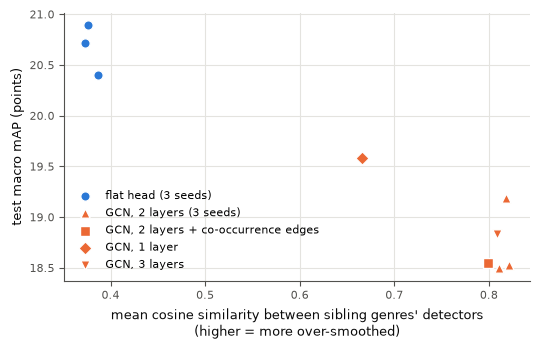

In [4]:
pairs = A.sibling_pairs(meta["genre_ids"], meta["parents"])
group = {**{r: "flat head" for r in FLAT}, **{r: "GCN, 2 layers" for r in GCN},
         "e3_gcn_1layer_s0": "GCN, 1 layer", "e3_gcn_3layer_s0": "GCN, 3 layers",
         "e2_gcn_cooc_s0": "GCN, 2 layers + co-occurrence edges"}
rows = []
for run in CNN_RUNS:
    model = A.load_best_model(config(run), meta["genre_ids"], meta["parents"])
    rows.append({"name": run, "group": group[run],
                 "sibling_cosine": A.mean_pair_cosine(A.detectors(model.head), pairs),
                 "map_all": table.loc[run, "map_all"]})
smoothing = pd.DataFrame(rows)
smoothing.round(4).to_csv(TAB / "oversmoothing.csv", index=False)
save(A.plot_oversmoothing(smoothing), "oversmoothing.png")
smoothing.round(3)

## E1 by genre: GCN − flat average precision (3-seed means)

GCN better on 25 of 97 genres
saved report/figures/ap_difference_top_level.png


saved report/figures/ap_difference_vs_training_tracks.png


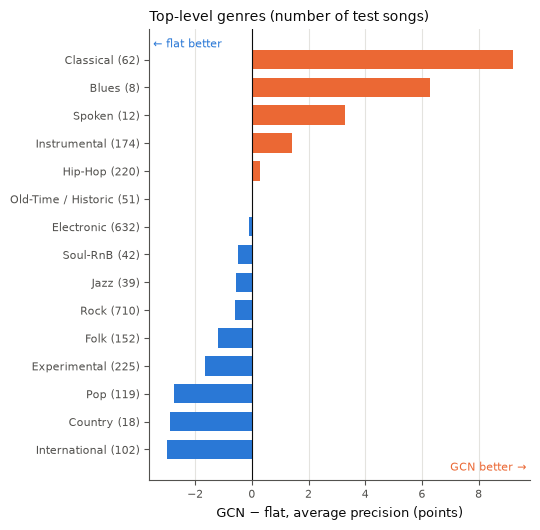

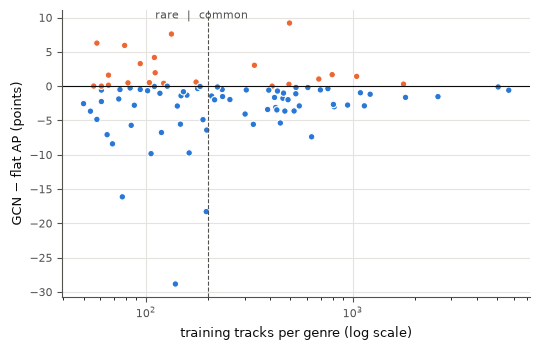

In [5]:
flat_ap, gcn_ap = A.mean_genre_ap(FLAT, RESULTS), A.mean_genre_ap(GCN, RESULTS)
n_test = pd.Series(A.load_scores(RESULTS, "e0_cnn_flat")["Y"].sum(axis=0), index=meta["genre_ids"])
by_genre = pd.DataFrame({"genre": [names[g] for g in meta["genre_ids"]],
                         "top_level": [meta["parents"].get(g, 0) == 0 for g in meta["genre_ids"]],
                         "train_tracks": meta["train_counts"], "test_songs": n_test.to_numpy(),
                         "flat_ap": flat_ap.to_numpy(), "gcn_ap": gcn_ap.to_numpy()}, index=meta["genre_ids"])
by_genre["gcn_minus_flat"] = by_genre["gcn_ap"] - by_genre["flat_ap"]
by_genre.round(4).to_csv(TAB / "ap_by_genre.csv")
print(f"GCN better on {(by_genre.gcn_minus_flat > 0).sum()} of {len(by_genre)} genres")

top = by_genre[by_genre.top_level].set_index("genre")
save(A.plot_ap_difference(top["gcn_minus_flat"], top["test_songs"],
                          title="Top-level genres (number of test songs)"), "ap_difference_top_level.png")
known = by_genre.dropna(subset=["gcn_minus_flat"])
save(A.plot_ap_difference_vs_training_tracks(known["gcn_minus_flat"], known["train_tracks"]),
     "ap_difference_vs_training_tracks.png")

## Diagnostic: per-genre detector updates (gradient norms)

Uses the local spectrogram cache, whatever clips it holds (199 on Maddi's laptop).

In [6]:
from tiny_timbre.data import load_splits

mels, splits, _ = load_splits(MELS_DIR, META_DIR)
clip_rows = np.concatenate([s["rows"] for s in splits.values()])
clip_Y = np.concatenate([s["Y"] for s in splits.values()])
rare = meta["train_counts"] < 200
updates = []
for run in FLAT + GCN:
    model = A.load_best_model(config(run), meta["genre_ids"], meta["parents"])
    x = A.encode_clips(model, mels, clip_rows)
    U = A.detector_updates(model.head, x, clip_Y)
    updates.append({"run": run, "head": "flat" if run in FLAT else "gcn", **A.update_summary(U, rare, pairs)})
updates = pd.DataFrame(updates)
updates.round(4).to_csv(TAB / "detector_updates.csv", index=False)
print(len(clip_rows), "clips")
updates.round(3)

199 clips


,run,head,rare_over_common,sibling_cosine
0,e0_cnn_flat,flat,0.400,0.712
1,e1_flat_s1,flat,0.332,0.775
2,e1_flat_s2,flat,0.426,0.642
3,e1_gcn_s0,gcn,0.770,0.946
4,e1_gcn_s1,gcn,0.725,0.946
5,e1_gcn_s2,gcn,0.733,0.942


## Diagnostic: encoder feature maps (block 2), flat model

Hip-Hop and Rock: the first local clip of each. Classical (no local clip): the first Classical
track in FMA-medium, fetched from the public zip by the demo's downloader.

/Users/msmith05/Documents/03 Projects/tiny-timbre/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


saved report/figures/feature_maps_block2.png


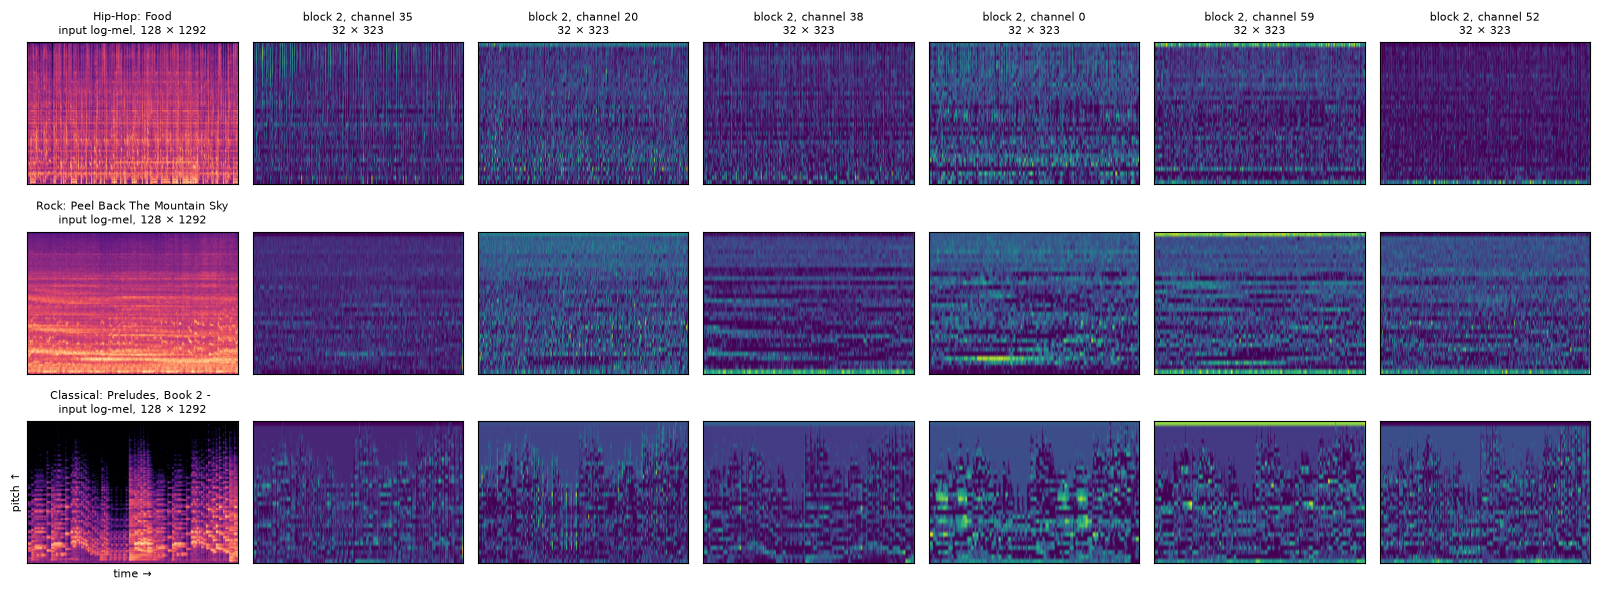

In [7]:
from tiny_timbre.data import compute_logmel, load_audio, load_logmel_cache
from tiny_timbre.demo import AudioSource
from tiny_timbre.labels import load_tracks, medium_tracks

cache, index = load_logmel_cache(MELS_DIR)
ok = index[index.status == "ok"].sort_values("track_id")
clips, titles = {}, {}
for genre in ["Hip-Hop", "Rock"]:
    first = ok[ok.genre_top == genre].iloc[0]
    clips[genre], titles[genre] = np.asarray(cache[int(first.row)], dtype=np.float32), meta["titles"].loc[int(first.track_id), "title"]
tracks = medium_tracks(load_tracks(f"{META_DIR}/tracks.csv"))
audio = AudioSource("data/fma_medium", "data/demo_audio")
for tid in tracks.index[tracks[("track", "genre_top")] == "Classical"]:
    path = audio.path(int(tid))
    if path:
        clips["Classical"], titles["Classical"] = compute_logmel(load_audio(path)), meta["titles"].loc[int(tid), "title"]
        break

model = A.load_best_model(config("e0_cnn_flat"), meta["genre_ids"], meta["parents"])
save(A.plot_feature_maps_by_genre(model, clips, {g: t[:28] for g, t in titles.items()}), "feature_maps_block2.png", dpi=110)

## E4: genre overlap@10 (recommendations; seed-0 flat and GCN models)

In [8]:
from tiny_timbre.demo import load_demo

e4 = load_demo(RESULTS, META_DIR).rec.overall(10)
e4.round(4).to_csv(TAB / "e4_overlap.csv")
e4.round(3)

,all,top_level,fine_grained,rare
GCN head,0.301,0.301,0.280,0.170
Flat head,0.307,0.308,0.287,0.180
features.csv,0.230,0.231,0.220,0.132
random,0.067,0.067,0.072,0.039


## Training curves (from W&B)

Needs a W&B login on this computer for our server, once:
`uv run wandb login --host https://api.forge.coreweave.com`

saved report/figures/train_loss.png
saved report/figures/val_map.png


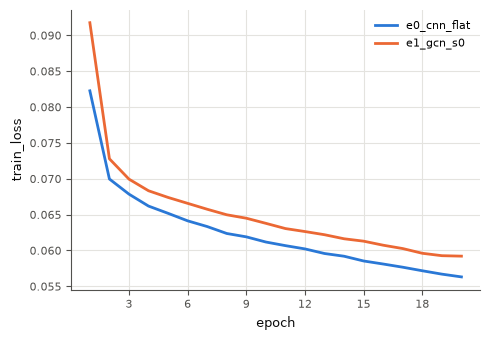

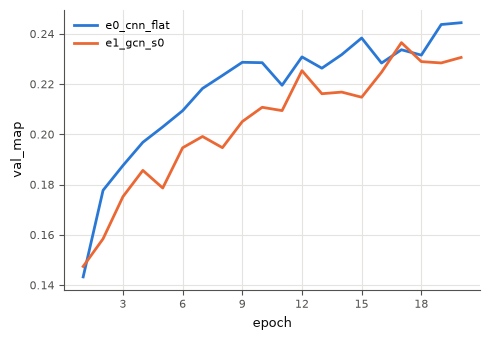

In [9]:
try:
    histories = {run: A.fetch_history("tiny-timbre-team", "tiny-timbre", run,
                                      base_url="https://api.forge.coreweave.com")
                 for run in ["e0_cnn_flat", "e1_gcn_s0"]}
    save(A.plot_curves(histories, "train_loss"), "train_loss.png")
    save(A.plot_curves(histories, "val_map"), "val_map.png")
except Exception as e:
    print("W&B not reachable from here, skipped:", type(e).__name__, str(e)[:200])

## Metadata audit list

Most confident model–tag disagreements of the best model (flat, seed 0). **Pending a team decision**:
the raw top 30 is mostly one artist; see HYPOTHESES.md.

In [10]:
audit = A.audit_table("e0_cnn_flat", RESULTS, meta["titles"], meta["genre_names"], top_k=30)
audit.to_csv("report/audit_e0_cnn_flat.csv", index=False)
audit[["title", "artist", "genre", "model_prob", "kind"]].head(10)

,title,artist,genre,model_prob,kind
0,"Brownie, You're Doing a Heck of a Job",Ted Hearne,Composed Music,0.000006,model_missed_tag
1,Eraser,Pianochocolate,New Age,0.000012,model_missed_tag
2,Hurt,Glass Candy,Soul-RnB,0.000023,model_missed_tag
3,Love On a Plate,Glass Candy,Soul-RnB,0.000030,model_missed_tag
4,The Screamers,Glass Candy,Soul-RnB,0.000033,model_missed_tag
5,WALKING WITH SAAD,Ed Saad,Thrash,0.000036,model_missed_tag
6,Crystal Migraine,Glass Candy,Soul-RnB,0.000037,model_missed_tag
7,Love Love Love,Glass Candy,Soul-RnB,0.000054,model_missed_tag
8,OVER FIVE YEARS,Ed Saad,Thrash,0.000063,model_missed_tag
9,Windmills & Lantarnlights,Julien Mier,Dubstep,0.000068,model_missed_tag


## Interpretability: linear probe on the song vectors (`probe.py`)

Can a linear regression read features.csv's hand-made measurements back out of each model's
256-number song vector? Test R² per feature family; random vectors are the "no information"
reference. Runs on the laptop from the two `*_embeddings.npz`.

saved report/figures/probe_r2.png


,group,flat head,GCN head,random vectors
chroma_stft,harmony,0.484,0.464,-0.008
chroma_cqt,harmony,0.358,0.296,-0.006
chroma_cens,harmony,0.220,0.139,-0.005
tonnetz,harmony,0.150,0.112,-0.006
rmse,loudness,0.334,0.339,-0.008
zcr,noisiness,0.553,0.554,-0.008
spectral_rolloff,timbre,0.704,0.701,-0.006
spectral_centroid,timbre,0.679,0.672,-0.005
spectral_bandwidth,timbre,0.679,0.683,-0.004
spectral_contrast,timbre,0.650,0.657,-0.009


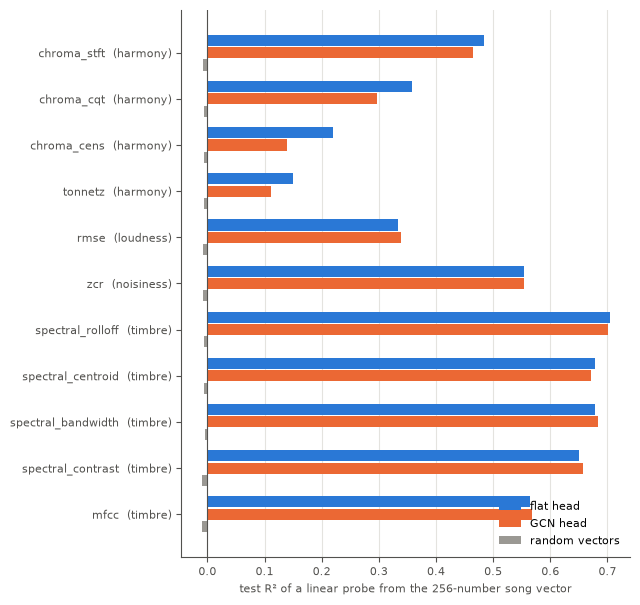

In [11]:
from tiny_timbre import probe as P
from tiny_timbre.baseline import load_features

features = load_features(f"{META_DIR}/features.csv")
probes = P.probe_table({"flat head": f"{RESULTS}/e0_cnn_flat_embeddings.npz",
                        "GCN head": f"{RESULTS}/e1_gcn_s0_embeddings.npz"}, features)
probes.round(4).to_csv(TAB / "probe_r2.csv")
save(P.plot_probe(probes), "probe_r2.png")
probes.round(3)

## Interpretability: occlusion (`occlusion.py`)

Needs `data/results/occlusion_<run>_<axis>.csv` from `notebooks/occlusion_colab.ipynb` (download
them from Drive's `results/`). Each cell: how many percentage points the model's confidence in the song's true top-level
genre drops when that stripe of the spectrogram is blanked. Row labels give the starting
confidence (a drop can't be bigger), so genres the model barely recognises stay near 0.

saved report/figures/occlusion_frequency.png


,0–393 Hz,419–812 Hz,"838–1,270 Hz","1,304–1,956 Hz","2,010–3,014 Hz","3,096–4,644 Hz","4,771–7,155 Hz","7,351–11,025 Hz",confidence
Blues,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
Classical,21.0,17.0,15.0,12.0,8.0,2.0,-0.0,-2.0,23.0
Country,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
Electronic,-3.0,-7.0,-9.0,-8.0,-7.0,-6.0,-5.0,0.0,69.0
Experimental,-21.0,-3.0,-9.0,-6.0,-5.0,-5.0,-6.0,-6.0,30.0
Folk,16.0,16.0,16.0,16.0,15.0,14.0,12.0,11.0,17.0
Hip-Hop,22.0,65.0,32.0,25.0,23.0,23.0,23.0,19.0,79.0
Instrumental,9.0,-28.0,-14.0,-9.0,-8.0,-8.0,-7.0,-6.0,21.0
International,21.0,23.0,21.0,22.0,21.0,20.0,14.0,13.0,24.0
Jazz,4.0,4.0,3.0,4.0,4.0,3.0,2.0,5.0,10.0


saved report/figures/occlusion_time.png


,0–5 s,5–10 s,10–15 s,15–20 s,20–25 s,25–30 s,confidence
Blues,1.0,1.0,1.0,1.0,1.0,1.0,1.0
Classical,7.0,9.0,9.0,6.0,8.0,8.0,23.0
Country,1.0,1.0,1.0,1.0,1.0,1.0,2.0
Electronic,4.0,3.0,4.0,5.0,4.0,5.0,69.0
Experimental,2.0,3.0,0.0,1.0,3.0,2.0,30.0
Folk,7.0,9.0,9.0,9.0,10.0,8.0,17.0
Hip-Hop,1.0,3.0,3.0,1.0,3.0,2.0,79.0
Instrumental,4.0,6.0,5.0,5.0,6.0,6.0,21.0
International,15.0,18.0,18.0,17.0,18.0,17.0,24.0
Jazz,3.0,6.0,5.0,5.0,6.0,5.0,10.0


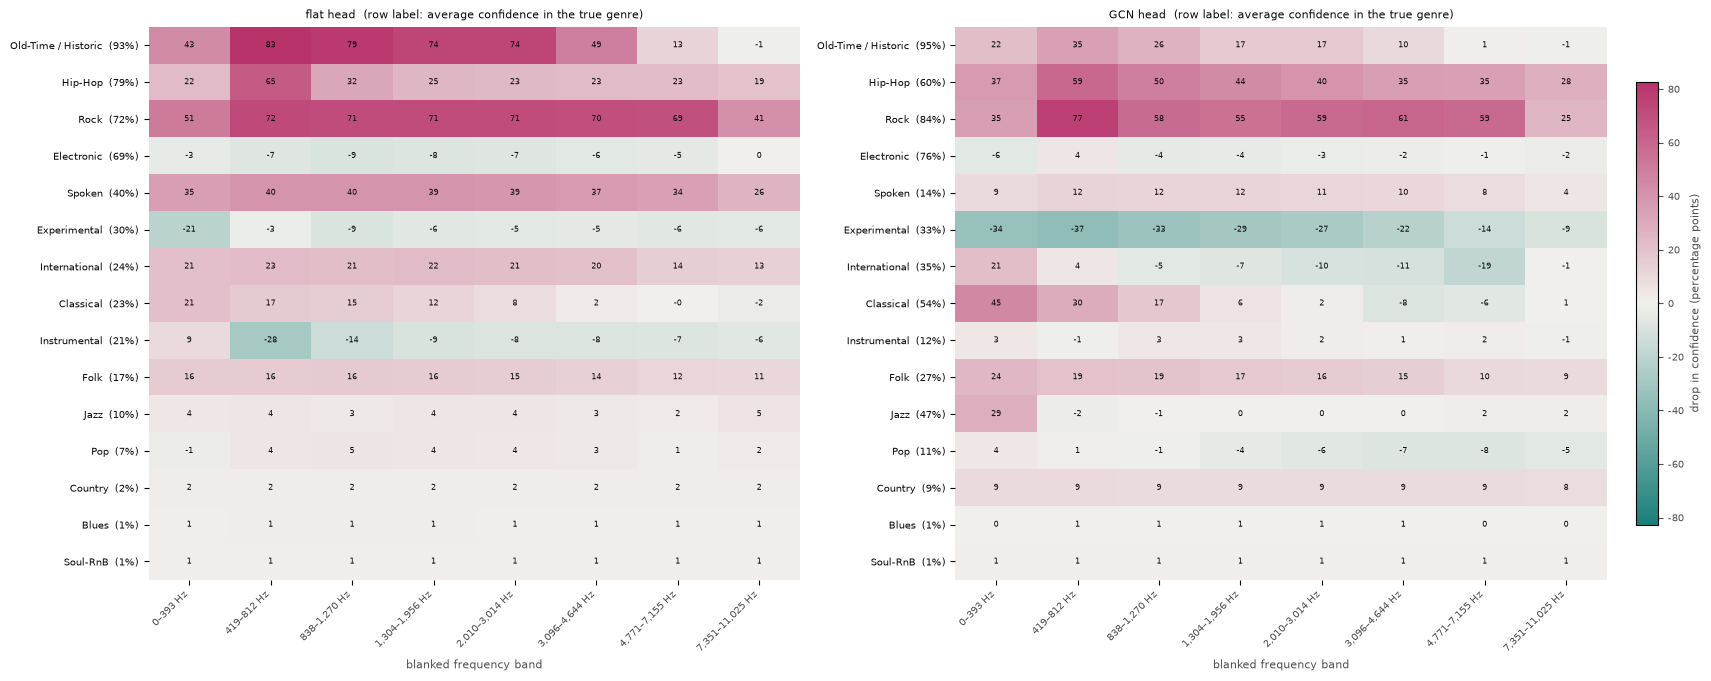

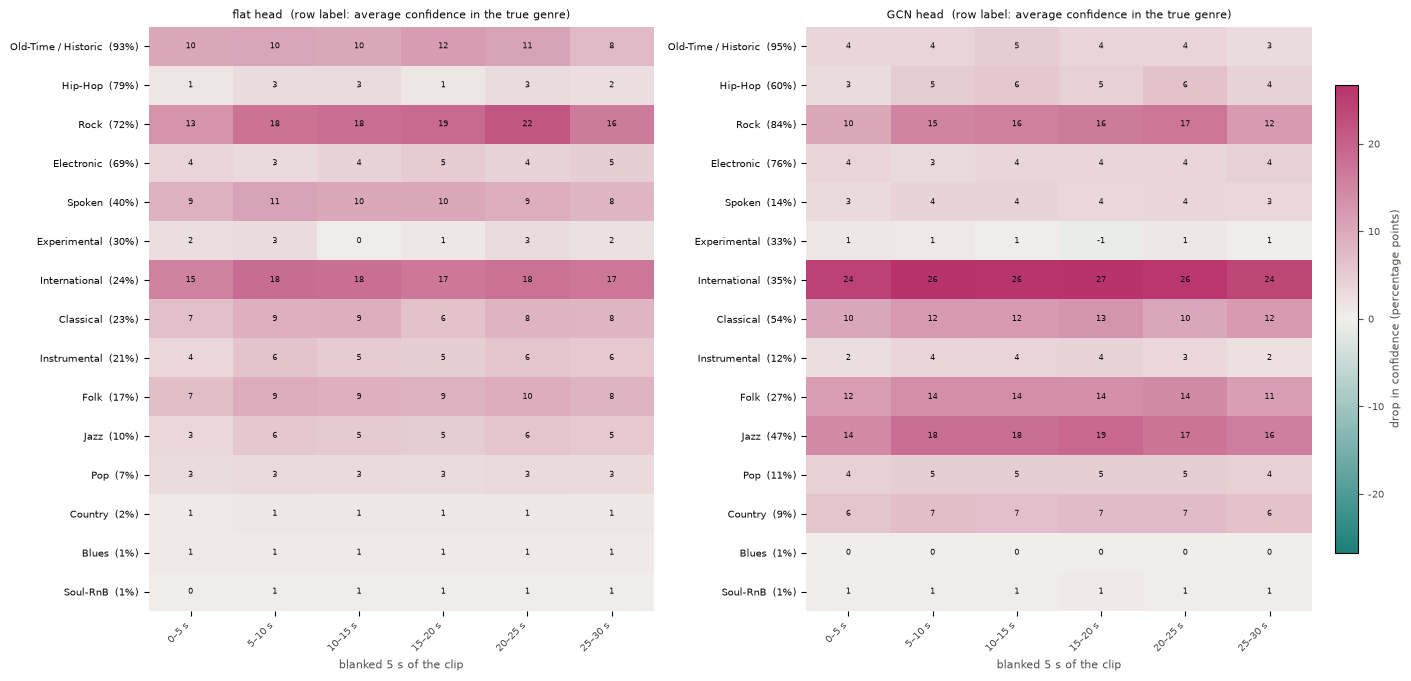

In [12]:
from tiny_timbre import occlusion as O

OCC_RUNS = {"flat head": "e0_cnn_flat", "GCN head": "e1_gcn_s0"}
for axis, xlabel in [("frequency", "blanked frequency band"), ("time", "blanked 5 s of the clip")]:
    paths = {label: Path(RESULTS) / f"occlusion_{run}_{axis}.csv" for label, run in OCC_RUNS.items()}
    if not all(p.exists() for p in paths.values()):
        print(f"{axis}: CSVs not downloaded yet, skipped")
        continue
    raw = {label: pd.read_csv(p) for label, p in paths.items()}
    summaries = {label: O.occlusion_summary(df) for label, df in raw.items()}   # drop, in probability
    confidence = {label: O.mean_confidence(df) for label, df in raw.items()}
    for label, s in summaries.items():
        s.assign(confidence=confidence[label]).round(4).to_csv(TAB / f"occlusion_{OCC_RUNS[label]}_{axis}.csv")
    save(O.plot_occlusion(summaries, confidence, xlabel), f"occlusion_{axis}.png")
    display((100 * summaries["flat head"].assign(confidence=confidence["flat head"])).round(0))